# Face registration with landmarks — first prototype

**The goal.** Every face photo is different. The eyes, the nose and the mouth are in
different places. We want to **change the shape of each photo**, so that the eyes, the
nose and the mouth are in the **same places** as in a reference face.
This is called *image registration*.

**The plan.** This is a small test before the full project. There are 4 steps:

1. Find important points on each face: eyes, nose, mouth and jaw.
   We call these points **landmarks**.
2. Make an **average face** from 10 photos.
3. Take a **new photo**. Change its shape so it fits the average face.
4. Check the result with numbers and with pictures.

**The photos.** We use 60 people from a free face dataset called
*Labeled Faces in the Wild* (LFW). We use one photo for each person.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "src")
from facereg import LandmarkDetector, viz, metrics
from facereg.shape import generalized_procrustes, similarity_transform, apply_affine
from facereg.tps import similarity_warp
from facereg.pipeline import detect_folder, select_frontal, build_average_face, register

OUT = Path("results/prototype")
OUT.mkdir(parents=True, exist_ok=True)
SIZE = 256          # size of the output images (256 x 256 pixels)
N_TRAIN = 10        # number of photos used to build the average face

## Step 1. Find the landmarks

A **landmark detector** is a program that finds the important points on a face.
It uses a neural network that learned from many face photos.

We use **MediaPipe**, a free tool from Google. It finds 478 points on the face.
We only keep **68 points**. Most face tools use these same 68 points.
OpenFace (the tool in the project description) also uses them.

- Points 0–16: jaw line
- Points 17–26: eyebrows
- Points 27–35: nose
- Points 36–47: eyes
- Points 48–67: mouth

W0000 00:00:1795288763.563690  387950 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1795288763.577407  387956 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795288763.584788  387960 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Faces found: 60


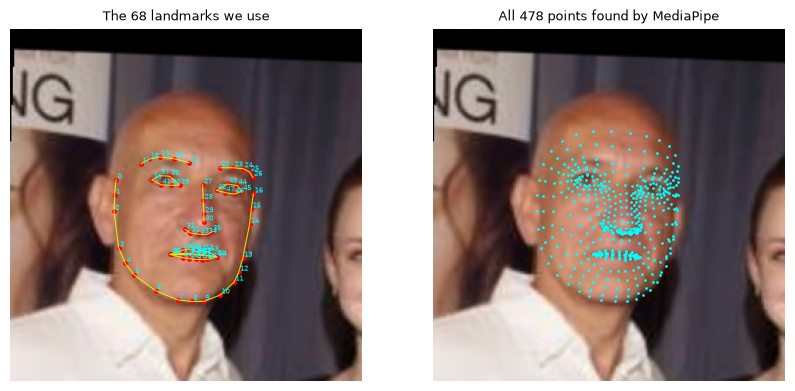

In [2]:
det = LandmarkDetector()
faces = detect_folder(det, "data/lfw")
print(f"Faces found: {len(faces)}")

f0 = faces[2]
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
viz.show_landmarks(ax[0], f0["img"], f0["pts"], "The 68 landmarks we use", numbers=True)
ax[1].imshow(viz.rgb(f0["img"])); ax[1].scatter(*f0["mesh"].T, s=1, c="cyan")
ax[1].set_title("All 478 points found by MediaPipe", fontsize=9); ax[1].axis("off")
viz.savefig(fig, OUT / "01_landmarks.png")

### Keep only faces that look at the camera
MediaPipe also tells us if the head is turned to the left or right (**yaw**),
or up or down (**pitch**).

For the average face, we only keep faces that are turned **less than 15°**.
Why? When the head is turned a lot, we cannot see part of the face.
A flat photo cannot show the hidden part, so we cannot fix it.

Faces looking at the camera: 40 of 60


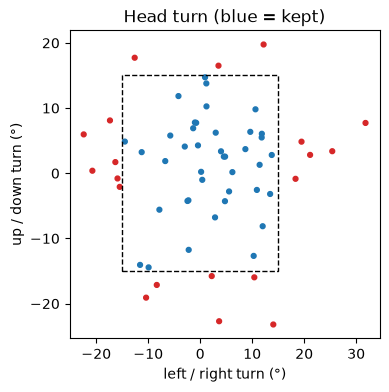

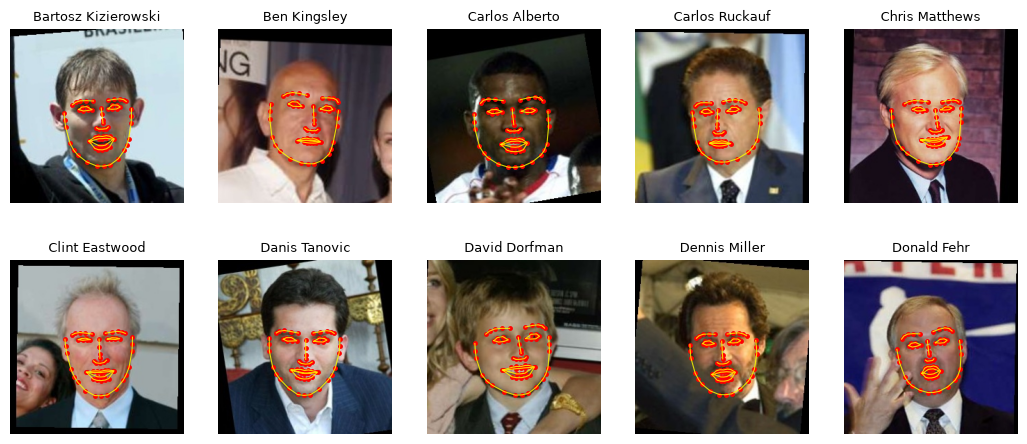

In [3]:
yaw = np.array([f["yaw"] for f in faces]); pitch = np.array([f["pitch"] for f in faces])
frontal = select_frontal(faces)
print(f"Faces looking at the camera: {len(frontal)} of {len(faces)}")

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(yaw, pitch, s=12, c=["tab:blue" if f in frontal else "tab:red" for f in faces])
ax.add_patch(plt.Rectangle((-15, -15), 30, 30, fill=False, ls="--"))
ax.set_xlabel("left / right turn (°)"); ax.set_ylabel("up / down turn (°)")
ax.set_title("Head turn (blue = kept)")
viz.savefig(fig, OUT / "02_head_pose.png")

train, test = frontal[:N_TRAIN], frontal[N_TRAIN]
fig, axs = plt.subplots(2, 5, figsize=(13, 5.5))
for a, f in zip(axs.ravel(), train):
    viz.show_landmarks(a, f["img"], f["pts"], f["name"].rsplit("_", 1)[0].replace("_", " "))
viz.savefig(fig, OUT / "03_training_faces.png")

## Step 2. Make the average face

1. **Average shape.** The faces have different sizes and positions in the photos.
   So first we move, turn and resize the 68 points of each face, so that all faces
   have the same size and position. This method is called *Procrustes alignment*.
   Then we calculate the average position of each point.
   This gives us the shape of an "average face".
2. **Average photo.** We change the shape of every photo so that its points are on the
   average shape. Then we calculate the average of all the photos.

The picture shows two average photos:
- **Middle:** the photos were only moved, turned and resized. The result is **blurry**,
  because the eyes and mouths are not in the same place.
- **Right:** the photos were also changed in shape (see Step 3).
  The result is **much clearer**.

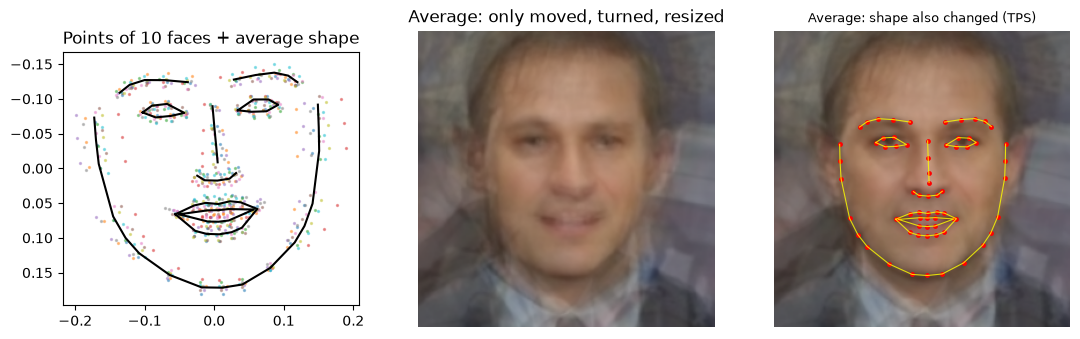

In [4]:
shapes = np.array([f["pts"] for f in train])
mean_norm, aligned = generalized_procrustes(shapes)
mean_pts, mean_img, warped = build_average_face(train, SIZE)
sim_avg = np.mean([similarity_warp(f["img"], f["pts"], mean_pts, SIZE)[0] for f in train],
                  axis=0).astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
for s in aligned:
    ax[0].scatter(s[:, 0], s[:, 1], s=2, alpha=0.4)
viz.draw_contours(ax[0], mean_norm, "k", lw=1.5)
ax[0].invert_yaxis(); ax[0].set_aspect("equal"); ax[0].set_title("Points of 10 faces + average shape")
ax[1].imshow(viz.rgb(sim_avg)); ax[1].set_title("Average: only moved, turned, resized"); ax[1].axis("off")
viz.show_landmarks(ax[2], mean_img, mean_pts, "Average: shape also changed (TPS)")
viz.savefig(fig, OUT / "04_average_face.png")

## Step 3. Change the shape of a new photo

We use a method called **thin-plate spline (TPS)**.

Imagine that the photo is printed on a thin sheet of rubber.
We take each of the 68 points and pull it to the same point on the average face.
The rubber between the points stretches in a smooth way.

- **Linear change:** we move, turn or resize the whole photo.
  All parts of the photo change in the same way.
- **Nonlinear change (TPS):** each part of the face can change in a different way.
  For example, TPS can make the mouth wider and not change the eyes.

TPS has one setting called **λ (lambda)**:
- **λ = 0** (we use this here): every point goes exactly to its place.
- **Bigger λ:** the change is smoother, but the points do not go exactly to their place.

We will try different values of λ in the full project.

**Important:** we did **not** use this test photo to make the average face.

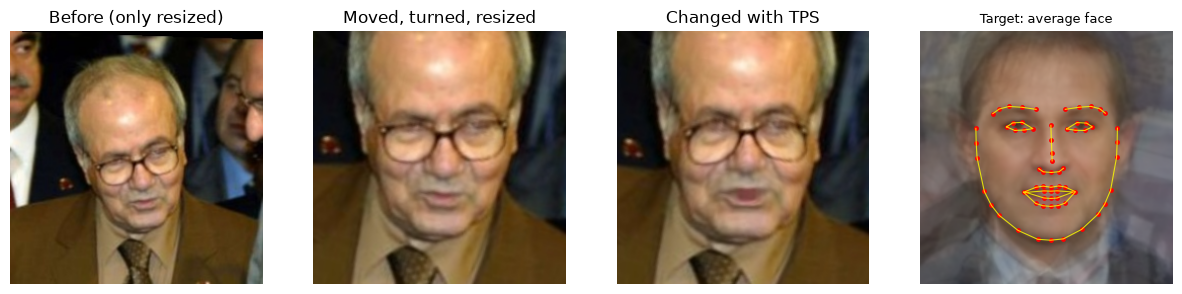

In [5]:
r = register(det, test["img"], test["pts"], mean_pts, mean_img, SIZE, lam=0.0)

fig, ax = plt.subplots(1, 4, figsize=(15, 4.2))
titles = {"none": "Before (only resized)", "similarity": "Moved, turned, resized", "tps": "Changed with TPS"}
for a, k in zip(ax, ["none", "similarity", "tps"]):
    a.imshow(viz.rgb(r["images"][k])); a.axis("off"); a.set_title(titles[k])
viz.show_landmarks(ax[3], mean_img, mean_pts, "Target: average face")
viz.savefig(fig, OUT / "05_registration.png")

**Left picture:** the yellow lines show how TPS changes the photo. In the final photo
these lines are straight. Here you can see that they bend around the face.

**Right picture:** how much TPS changes the face **more than** a simple move, turn and
resize. It is measured in pixels. Brighter colour = bigger change.

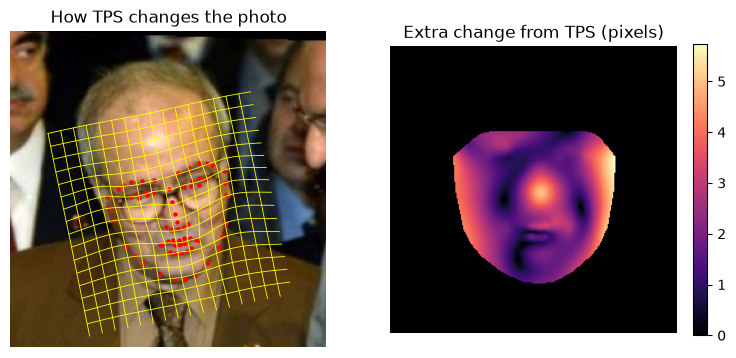

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
viz.show_grid(ax[0], *r["maps"], step=16, img=test["img"], color="yellow")
ax[0].scatter(*test["pts"].T, s=5, c="red"); ax[0].set_title("How TPS changes the photo")
ax[0].set_xlim(0, test["img"].shape[1]); ax[0].set_ylim(test["img"].shape[0], 0)
yy, xx = np.mgrid[0:SIZE, 0:SIZE]
grid = np.c_[xx.ravel(), yy.ravel()]
sim_map = apply_affine(similarity_transform(mean_pts, test["pts"]), grid).reshape(SIZE, SIZE, 2)
disp = np.linalg.norm(np.dstack(r["maps"]) - sim_map, axis=2)
im = ax[1].imshow(disp * r["mask"], cmap="magma"); plt.colorbar(im, ax=ax[1], fraction=0.046)
ax[1].set_title("Extra change from TPS (pixels)"); ax[1].axis("off")
viz.savefig(fig, OUT / "06_deformation.png")

## Step 4. Check the result

### With numbers
After we change the photo, we find the landmarks **again** on the new photo.
Then we measure the distance between each point and its correct place on the average face.

We do this for 3 versions of the photo:
1. Before (the photo is only resized)
2. Only moved, turned and resized
3. Changed with TPS

What the numbers mean (**smaller is better** for all of them):
- **Mean error (pixels):** the average distance between the points and their correct place.
- **Error / eye distance:** the same error, divided by the distance between the eyes.
  So 0.05 means "5% of the distance between the eyes".
  With this number we can compare photos of different sizes.
- **Brightness difference:** how different the face looks from the average face.

In [7]:
table = pd.DataFrame({
    "mean error (pixels)": {k: r["err"][k].mean() for k in r["err"]},
    "error / eye distance": r["nme"],
    "brightness difference": r["mad"],
}).loc[["none", "similarity", "tps"]]
table.index = [titles[k] for k in ["none", "similarity", "tps"]]
table.to_csv(OUT / "metrics_single_image.csv")
table.round(3)

,mean error (pixels),error / eye distance,brightness difference
Before (only resized),24.161,0.278,1.107
"Moved, turned, resized",3.934,0.045,0.629
Changed with TPS,2.059,0.024,0.606


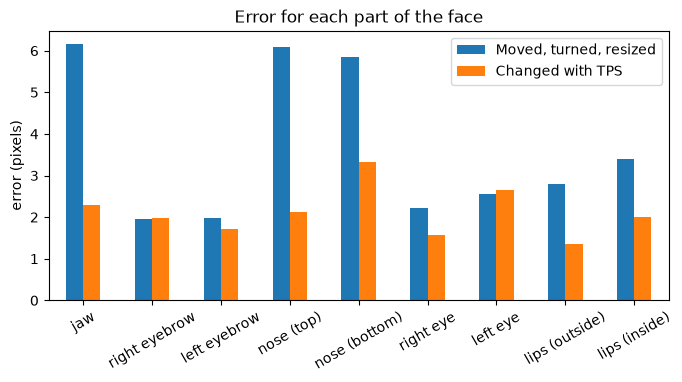

In [8]:
from facereg.landmarks import REGIONS
names = {"jaw": "jaw", "right_brow": "right eyebrow", "left_brow": "left eyebrow",
         "nose_bridge": "nose (top)", "nose_base": "nose (bottom)", "right_eye": "right eye",
         "left_eye": "left eye", "outer_lips": "lips (outside)", "inner_lips": "lips (inside)"}
reg_err = pd.DataFrame({titles[k]: {names[reg]: r["err"][k][idx].mean() for reg, idx in REGIONS.items()}
                        for k in ["similarity", "tps"]})
ax = reg_err.plot.bar(figsize=(8, 3.5), rot=30); ax.set_ylabel("error (pixels)")
ax.set_title("Error for each part of the face")
viz.savefig(ax.figure, OUT / "07_error_per_region.png")

### With pictures
- **Top row: difference pictures.** Bright areas show where the photo and the average face
  are different.
- **Bottom row: face lines.** **Green** = lines of the average face.
  **Red** = lines found on the photo. When the lines are close, the result is good.

Note: this person wears **glasses**. The glasses are still bright in the difference
picture after TPS, because the average face has no glasses. This is an example of a
**limitation**: when something covers part of the face, the result is worse.

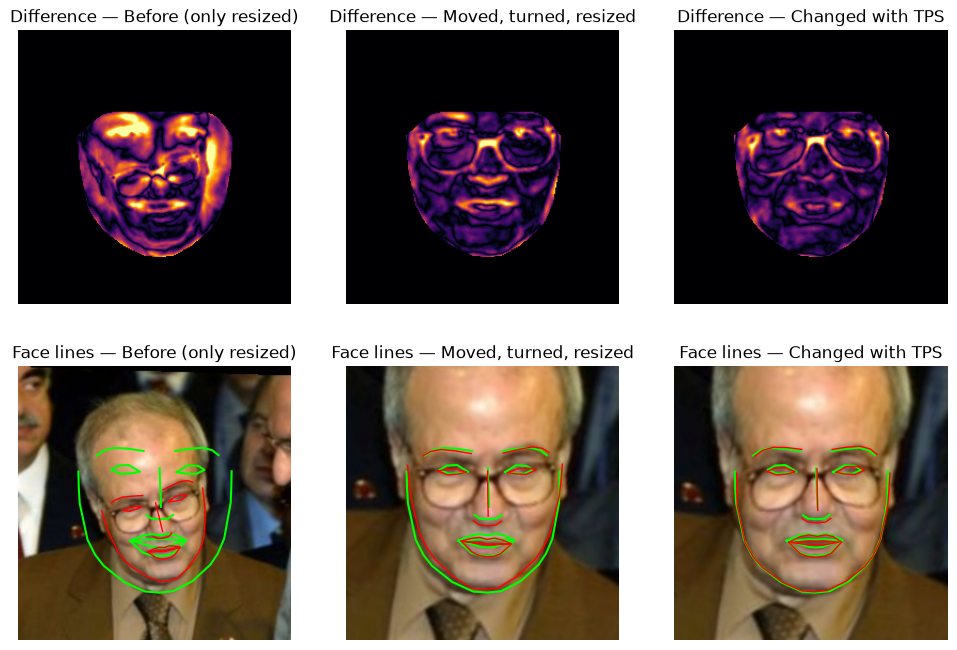

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for j, k in enumerate(["none", "similarity", "tps"]):
    d = metrics.difference_image(r["images"][k], mean_img, r["mask"])
    ax[0, j].imshow(d * r["mask"], cmap="inferno", vmin=0, vmax=3)
    ax[0, j].set_title(f"Difference — {titles[k]}"); ax[0, j].axis("off")
    ax[1, j].imshow(viz.rgb(r["images"][k]))
    viz.draw_contours(ax[1, j], mean_pts, "lime", lw=1.5)
    if r["pts"][k] is not None:
        viz.draw_contours(ax[1, j], r["pts"][k], "red", lw=1.0)
    ax[1, j].set_title(f"Face lines — {titles[k]}"); ax[1, j].axis("off")
viz.savefig(fig, OUT / "08_difference_and_contours.png")

## Summary

- The error is much smaller after TPS:
  - before: about **24 pixels**
  - after moving, turning and resizing: about **4 pixels**
  - after TPS: about **2 pixels**
- TPS helps most with the **jaw** and the **nose**. For these parts the error goes from
  about 6 pixels to 2–3 pixels. The eyebrows were already in a good place.

## Next steps (full project)

- Use all the photos, not only 10. Test many new photos, not only one.
- Use only some of the points (for example, only eyes and mouth). Compare the results.
- Try different values of λ.
- Test with my own photos: smiling, head turned, and part of the face covered
  (glasses, hand). This will show the limitations of the method.